# CamemBERT fine-tuné pour la NER (Français / SunuNER)

Fine-tuning du modèle pré-entraîné `camembert-base` avec `transformers` (Hugging Face) pour la tâche de classification de tokens (NER).

**Corpus** : `Corpus.conll` — 1309 phrases annotées en français (Label Studio → CoNLL, schéma BIO)
Entités : `PER`, `LOC`, `ORG`, `MISC`

Ce notebook est structuré en 6 sections :
1. Importation des bibliothèques
2. Variables, montage de Google Drive et chargement du corpus
3. Split Train / Validation / Test
4. Entraînement du modèle
5. Évaluation (Précision, Rappel, F1, ...)
6. Matrice de confusion


## 1. Importation des bibliothèques

In [ ]:
!pip install --upgrade pip
!pip -q install transformers datasets seqeval accelerate evaluate

import os
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from datasets import Dataset, DatasetDict
from transformers import (
    AutoTokenizer,
    AutoModelForTokenClassification,
    TrainingArguments,
    Trainer,
    DataCollatorForTokenClassification,
)
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from seqeval.metrics import classification_report as seqeval_report
from seqeval.metrics import precision_score, recall_score, f1_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device :", device)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 31.5 MB/s eta 0:00:00
  Attempting uninstall: pip
    Found existing installation: pip 24.1.2
    Uninstalling pip-24.1.2:
      Successfully uninstalled pip-24.1.2
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
Device : cuda


## 2. Variables, montage de Google Drive et chargement du corpus annoté

In [ ]:
# --- Montage de Google Drive (Colab) ---
from google.colab import drive
drive.mount('/content/drive')

# --- Variables globales ---
DRIVE_ROOT = "/content/drive/MyDrive/Colab Notebooks/S4"       # dossier racine du projet sur Drive (à adapter)
CORPUS_PATH = f"{DRIVE_ROOT}/sununer_corpus.conll"         # fichier CoNLL issu de Label Studio
RANDOM_SEED = 42

TRAIN_RATIO = 0.70
VAL_RATIO   = 0.15
TEST_RATIO  = 0.15

import os
assert os.path.exists(CORPUS_PATH), f"Corpus introuvable : {CORPUS_PATH} — vérifier le chemin sur Drive."
print("Corpus trouvé :", CORPUS_PATH)

MODEL_CHECKPOINT = "camembert-base"
OUTPUT_DIR = f"{DRIVE_ROOT}/camembert_ner_model"


Mounted at /content/drive
Corpus trouvé : /content/drive/MyDrive/Colab Notebooks/S4/sununer_corpus.conll


In [ ]:
import re

# --- Chargement du corpus CoNLL (format BIO : "token\tTAG", phrases séparées par une ligne vide) ---
def load_conll(path):
    """Charge un fichier CoNLL et renvoie une liste de phrases.
    Chaque phrase est une liste de tuples (token, tag)."""
    sentences = []
    current = []
    with open(path, encoding="utf-8") as f:
        for line in f:
            line = line.rstrip("\n")
            if not line: # Empty line signals end of sentence
                if current:
                    sentences.append(current)
                    current = []
                continue
            if line.startswith("#"): # Ignore comment lines (e.g., from Label Studio exports)
                continue

            # tolère "token tag" ou "token\ttag"
            parts = re.split(r'\s+|\t', line)
            if len(parts) < 2: # Ensure there are at least two parts (token and tag)
                continue
            token, tag = parts[0], parts[-1]
            current.append((token, tag))
    if current:
        sentences.append(current)
    return sentences

sentences = load_conll(CORPUS_PATH)
print(f"Nombre de phrases chargées : {len(sentences)}")
print("Exemple de phrase :", sentences[0][:10])

# Liste des étiquettes présentes dans le corpus
all_tags = sorted({tag for sent in sentences for _, tag in sent})
print("Étiquettes (BIO) présentes :", all_tags)

Nombre de phrases chargées : 1309
Exemple de phrase : [('Macky', 'B-PER'), ('Sall', 'I-PER'), ('à', 'O'), ('Dakar', 'B-LOC'), (':', 'O'), ('La', 'O'), ('date', 'O'), ('de', 'O'), ('sa', 'O'), ('rencontre', 'O')]
Étiquettes (BIO) présentes : ['B-LOC', 'B-MISC', 'B-ORG', 'B-PER', 'I-LOC', 'I-MISC', 'I-ORG', 'I-PER', 'O']


## 3. Split Train / Validation / Test

In [ ]:
from sklearn.model_selection import train_test_split

train_sents, temp_sents = train_test_split(
    sentences, test_size=(1 - TRAIN_RATIO), random_state=RANDOM_SEED
)
val_sents, test_sents = train_test_split(
    temp_sents, test_size=TEST_RATIO / (TEST_RATIO + VAL_RATIO), random_state=RANDOM_SEED
)

print(f"Train : {len(train_sents)} phrases")
print(f"Validation : {len(val_sents)} phrases")
print(f"Test : {len(test_sents)} phrases")

# --- Conversion au format datasets (Hugging Face) ---
label_list = sorted(all_tags)
label2id = {l: i for i, l in enumerate(label_list)}
id2label = {i: l for l, i in label2id.items()}

def sentences_to_hf_dict(sents):
    return {
        "tokens": [[tok for tok, _ in s] for s in sents],
        "ner_tags": [[label2id[tag] for _, tag in s] for s in sents],
    }

raw_datasets = DatasetDict({
    "train": Dataset.from_dict(sentences_to_hf_dict(train_sents)),
    "validation": Dataset.from_dict(sentences_to_hf_dict(val_sents)),
    "test": Dataset.from_dict(sentences_to_hf_dict(test_sents)),
})
raw_datasets


Train : 916 phrases
Validation : 196 phrases
Test : 197 phrases


DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 916
    })
    validation: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 196
    })
    test: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 197
    })
})

## 4. Entraînement du modèle

In [ ]:
# --- Tokenisation + alignement des étiquettes sur les sous-mots ---
tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT, add_prefix_space=True)

def tokenize_and_align_labels(examples):
    tokenized_inputs = tokenizer(
        examples["tokens"], truncation=True, is_split_into_words=True
    )
    all_labels = []
    for i, labels in enumerate(examples["ner_tags"]):
        word_ids = tokenized_inputs.word_ids(batch_index=i)
        previous_word_idx = None
        label_ids = []
        for word_idx in word_ids:
            if word_idx is None:
                label_ids.append(-100)
            elif word_idx != previous_word_idx:
                label_ids.append(labels[word_idx])
            else:
                label_ids.append(-100)  # sous-mot : ignoré dans la loss
            previous_word_idx = word_idx
        all_labels.append(label_ids)
    tokenized_inputs["labels"] = all_labels
    return tokenized_inputs

tokenized_datasets = raw_datasets.map(tokenize_and_align_labels, batched=True)

data_collator = DataCollatorForTokenClassification(tokenizer=tokenizer)

# --- Modèle ---
model = AutoModelForTokenClassification.from_pretrained(
    MODEL_CHECKPOINT, num_labels=len(label_list), id2label=id2label, label2id=label2id
).to(device)

# --- Métriques calculées pendant l'entraînement (seqeval) ---
def compute_metrics(p):
    predictions, labels = p
    predictions = np.argmax(predictions, axis=2)

    true_predictions = [
        [id2label[p_] for (p_, l_) in zip(pred, lab) if l_ != -100]
        for pred, lab in zip(predictions, labels)
    ]
    true_labels = [
        [id2label[l_] for (p_, l_) in zip(pred, lab) if l_ != -100]
        for pred, lab in zip(predictions, labels)
    ]

    return {
        "precision": precision_score(true_labels, true_predictions),
        "recall": recall_score(true_labels, true_predictions),
        "f1": f1_score(true_labels, true_predictions),
    }

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=23,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    seed=SEED,
)

import inspect

trainer_kwargs = dict(
    model=model,
    args=training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

# Selon la version de `transformers`, le paramètre s'appelle "tokenizer" (ancien)
# ou "processing_class" (nouveau, >= 4.46). On détecte automatiquement le bon nom.
trainer_sig = inspect.signature(Trainer.__init__).parameters
if "processing_class" in trainer_sig:
    trainer_kwargs["processing_class"] = tokenizer
else:
    trainer_kwargs["tokenizer"] = tokenizer

trainer = Trainer(**trainer_kwargs)

trainer.train()


Map:   0%|          | 0/916 [00:00<?, ? examples/s]

Map:   0%|          | 0/196 [00:00<?, ? examples/s]

Map:   0%|          | 0/197 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] CamembertForTokenClassification LOAD REPORT from: camembert-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
classifier.weight           | MISSING    | 
classifier.bias             | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Precision,Recall,F1
1,No log,0.623906,0.000000,0.000000,0.000000
2,No log,0.394108,0.418848,0.396040,0.407125
3,No log,0.264268,0.633929,0.702970,0.666667
4,No log,0.185418,0.767442,0.816832,0.791367
5,0.505070,0.145224,0.773756,0.846535,0.808511
6,0.505070,0.115626,0.850679,0.930693,0.888889
7,0.505070,0.097764,0.876712,0.950495,0.912114
8,0.505070,0.083402,0.884793,0.950495,0.916468
9,0.126331,0.075920,0.897674,0.955446,0.925659
10,0.126331,0.066792,0.903226,0.970297,0.935561


... (21 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=2645, training_loss=0.15038691576577315, metrics={'train_runtime': 943.537, 'train_samples_per_second': 22.329, 'train_steps_per_second': 2.803, 'total_flos': 686570055525720.0, 'train_loss': 0.15038691576577315, 'epoch': 23.0})

## Courbe d'apprentissage

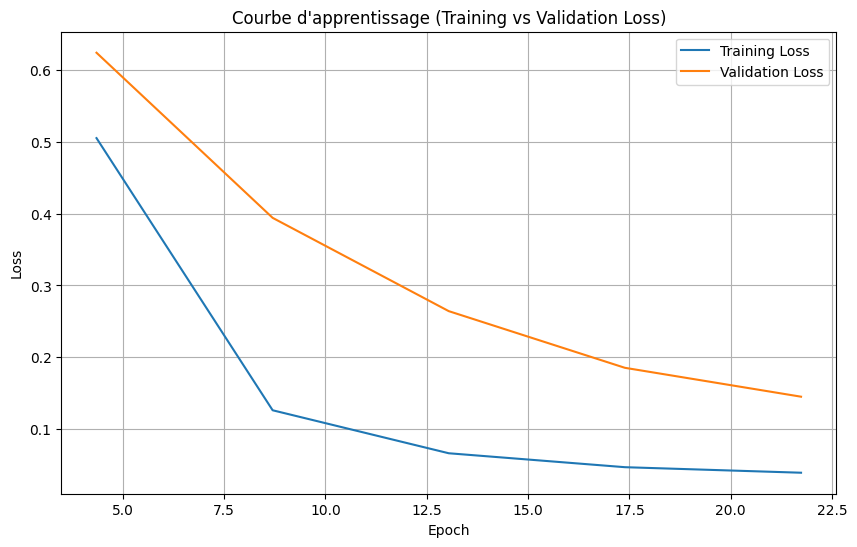

In [ ]:
import pandas as pd

# Extracting training and evaluation loss from trainer.state.log_history
log_history = trainer.state.log_history

# Filter for loss values, ignoring dictionary types that might appear in logs
train_losses = []
val_losses = []
epochs = []

for entry in log_history:
    if 'loss' in entry and 'eval_loss' not in entry: # Training loss
        train_losses.append(entry['loss'])
        epochs.append(entry['epoch'])
    elif 'eval_loss' in entry: # Validation loss
        val_losses.append(entry['eval_loss'])

# Ensure both lists are of the same length by trimming the longer one
# This handles cases where eval_loss is recorded at different intervals or if initial train_loss isn't paired
min_len = min(len(train_losses), len(val_losses), len(epochs))
train_losses = train_losses[:min_len]
val_losses = val_losses[:min_len]
epochs = epochs[:min_len]

plt.figure(figsize=(10, 6))
plt.plot(epochs, train_losses, label='Training Loss')
plt.plot(epochs, val_losses, label='Validation Loss')
plt.title("Courbe d'apprentissage (Training vs Validation Loss)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

### Detailed Training Evaluation

In [ ]:
predictions_train, labels_train, _ = trainer.predict(tokenized_datasets["train"])
predictions_train = np.argmax(predictions_train, axis=2)

y_train_true = [
    [id2label[l_] for (p_, l_) in zip(pred, lab) if l_ != -100]
    for pred, lab in zip(predictions_train, labels_train)
]
y_train_pred = [
    [id2label[p_] for (p_, l_) in zip(pred, lab) if l_ != -100]
    for pred, lab in zip(predictions_train, labels_train)
]

print("=== Detailed Évaluation sur TRAIN ===")
print(seqeval_report(y_train_true, y_train_pred, digits=4))

=== Detailed Évaluation sur TRAIN ===
              precision    recall  f1-score   support

         LOC     0.9881    1.0000    0.9940       249
        MISC     1.0000    1.0000    1.0000       115
         ORG     0.9850    0.9924    0.9887       264
         PER     0.9949    1.0000    0.9975       394

   micro avg     0.9913    0.9980    0.9946      1022
   macro avg     0.9920    0.9981    0.9950      1022
weighted avg     0.9913    0.9980    0.9946      1022



## 5. Évaluation (Précision, Rappel, F1, ...)

In [ ]:


# --- Évaluation détaillée sur le set de test ---
predictions, labels, _ = trainer.predict(tokenized_datasets["test"])
predictions = np.argmax(predictions, axis=2)

y_test_true = [
    [id2label[l_] for (p_, l_) in zip(pred, lab) if l_ != -100]
    for pred, lab in zip(predictions, labels)
]
y_test_pred = [
    [id2label[p_] for (p_, l_) in zip(pred, lab) if l_ != -100]
    for pred, lab in zip(predictions, labels)
]

print("=== Évaluation sur TEST ===")
print(seqeval_report(y_test_true, y_test_pred, digits=4))

print(f"Précision (test) : {precision_score(y_test_true, y_test_pred):.4f}")
print(f"Rappel (test)    : {recall_score(y_test_true, y_test_pred):.4f}")
print(f"F1-score (test)  : {f1_score(y_test_true, y_test_pred):.4f}")


=== Évaluation sur TEST ===
              precision    recall  f1-score   support

         LOC     0.8140    0.8974    0.8537        39
        MISC     0.5833    0.8077    0.6774        26
         ORG     0.8281    0.9138    0.8689        58
         PER     0.9452    0.9857    0.9650        70

   micro avg     0.8241    0.9223    0.8704       193
   macro avg     0.7927    0.9012    0.8412       193
weighted avg     0.8347    0.9223    0.8749       193

Précision (test) : 0.8241
Rappel (test)    : 0.9223
F1-score (test)  : 0.8704


### Detailed Validation Evaluation

In [ ]:
predictions_val, labels_val, _ = trainer.predict(tokenized_datasets["validation"])
predictions_val = np.argmax(predictions_val, axis=2)

y_val_true = [
    [id2label[l_] for (p_, l_) in zip(pred, lab) if l_ != -100]
    for pred, lab in zip(predictions_val, labels_val)
]
y_val_pred = [
    [id2label[p_] for (p_, l_) in zip(pred, lab) if l_ != -100]
    for pred, lab in zip(predictions_val, labels_val)
]

print("=== Detailed Évaluation sur VALIDATION ===")
print(seqeval_report(y_val_true, y_val_pred, digits=4))

=== Detailed Évaluation sur VALIDATION ===
              precision    recall  f1-score   support

         LOC     0.9423    0.9800    0.9608        50
        MISC     0.8400    1.0000    0.9130        21
         ORG     0.8644    0.9273    0.8947        55
         PER     0.9737    0.9737    0.9737        76

   micro avg     0.9198    0.9653    0.9420       202
   macro avg     0.9051    0.9702    0.9356       202
weighted avg     0.9223    0.9653    0.9427       202



## 6. Matrice de confusion

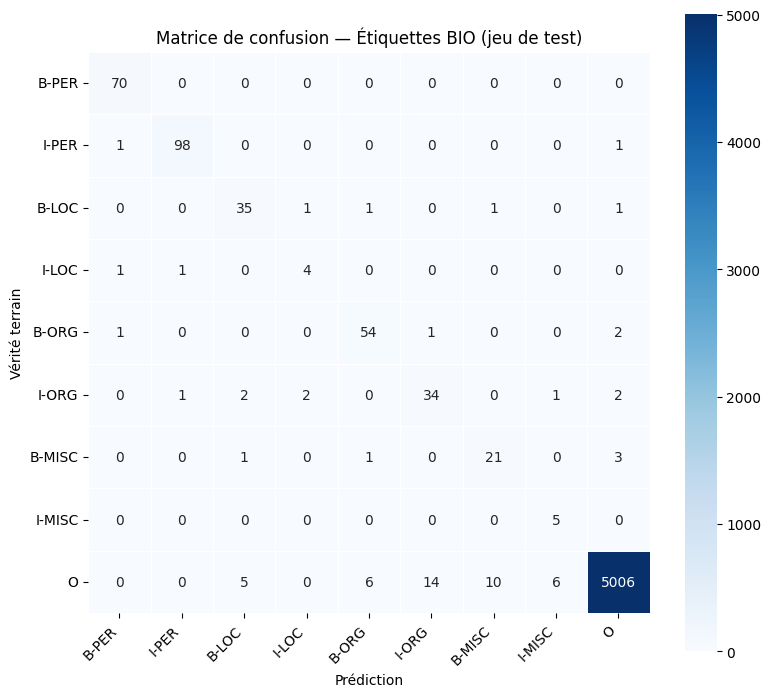

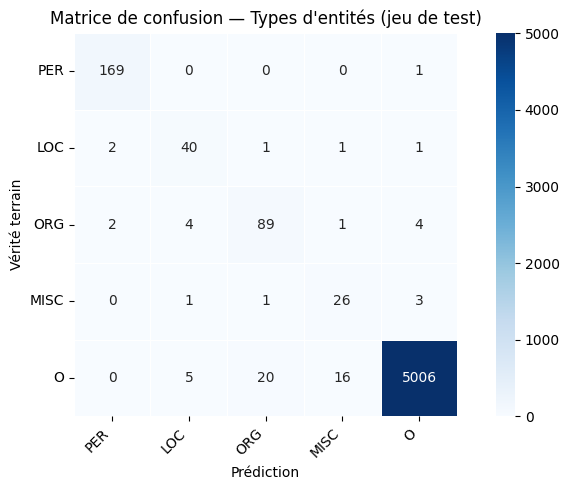

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix


def plot_cm(y_true_seqs, y_pred_seqs, labels_ordered, title):
    # 1. Vérifier le nombre de séquences
    if len(y_true_seqs) != len(y_pred_seqs):
        raise ValueError(
            "Le nombre de séquences réelles et prédites diffère."
        )

    # 2. Aplatir les séquences
    y_true_flat = [tag for seq in y_true_seqs for tag in seq]
    y_pred_flat = [tag for seq in y_pred_seqs for tag in seq]

    # 3. Vérifier l'alignement des tokens
    if len(y_true_flat) != len(y_pred_flat):
        raise ValueError(
            "Le nombre de tokens réels et prédits diffère."
        )

    # 4. Inclure toutes les classes réelles et prédites
    existing_labels = set(y_true_flat) | set(y_pred_flat)

    labels = [
        label for label in labels_ordered
        if label in existing_labels
    ]
    labels += sorted(existing_labels - set(labels))

    # 5. Calculer la matrice de confusion
    cm = confusion_matrix(
        y_true_flat,
        y_pred_flat,
        labels=labels
    )

    # 6. Afficher la matrice
    plt.figure(figsize=(
        max(8, 0.9 * len(labels)),
        max(5, 0.8 * len(labels))
    ))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=labels,
        yticklabels=labels,
        linewidths=0.5,
        square=True
    )

    plt.xlabel("Prédiction")
    plt.ylabel("Vérité terrain")
    plt.title(title)
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    return cm, labels


# ==================================================
#  MATRICE DE CONFUSION AU NIVEAU DES TAGS BIO
# ==================================================

labels_bio_ordered = [
    'B-PER', 'I-PER',
    'B-LOC', 'I-LOC',
    'B-ORG', 'I-ORG',
    'B-MISC', 'I-MISC',
    'O'
]

cm_bio, labels_bio = plot_cm(
    y_test_true,
    y_test_pred,
    labels_bio_ordered,
    "Matrice de confusion — Étiquettes BIO (jeu de test)"
)




